In [2]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.linear_model import LassoCV



In [3]:
#  Load Datasets
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

print("The shape of red wine dataset:  ", red.shape)
print("The shape of white wine dataset:", white.shape)

# Add type column
red['type'] = 0  # red
white['type'] = 1  # white

# combine both datasets into one
data = pd.concat([white, red], axis=0)
print("The shape of the combined datasets:", white.shape)

# check for duplicates
data.duplicated().value_counts()

# drop duplicates
data.drop_duplicates(inplace=True)
data.shape


The shape of red wine dataset:   (1599, 12)
The shape of white wine dataset: (4898, 12)
The shape of the combined datasets: (4898, 13)


(5320, 13)

# --- 1. Exploratory Data Analysis ---

In [5]:
# get summary statistics of all variables in the dataset 
# get the range and variance as well
ds = data.describe().transpose()
ds["range"] = ds["max"] - ds["min"]        
ds["variance"] = ds["std"]**2                   
ds

,count,mean,std,min,25%,50%,75%,max,range,variance
fixed acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000,12.10000,1.741531
volatile acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000,1.50000,0.028307
citric acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000,1.66000,0.021655
residual sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000,65.20000,20.251621
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100,0.60200,0.001359
free sulfur dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000,288.00000,317.019619
total sulfur dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000,434.00000,3223.312421
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898,0.05187,0.000009
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000,1.29000,0.025721
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000,1.78000,0.022423


**Question 1b**

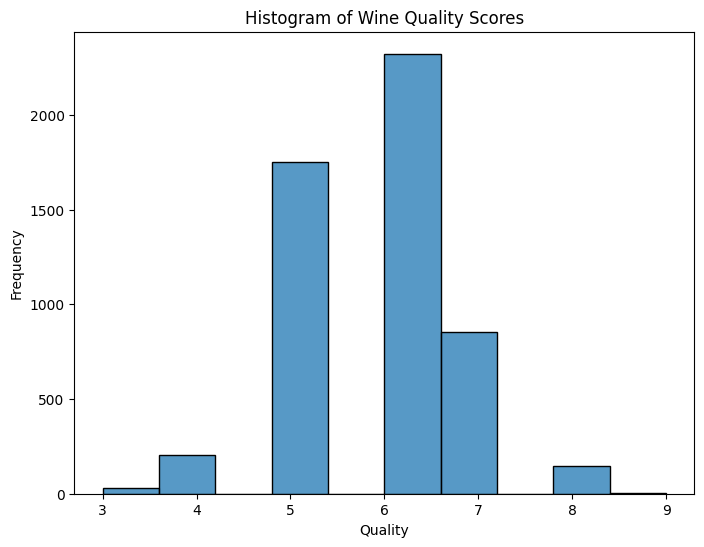

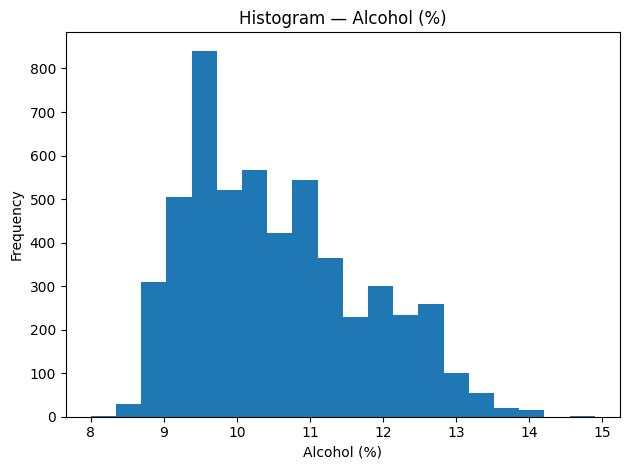

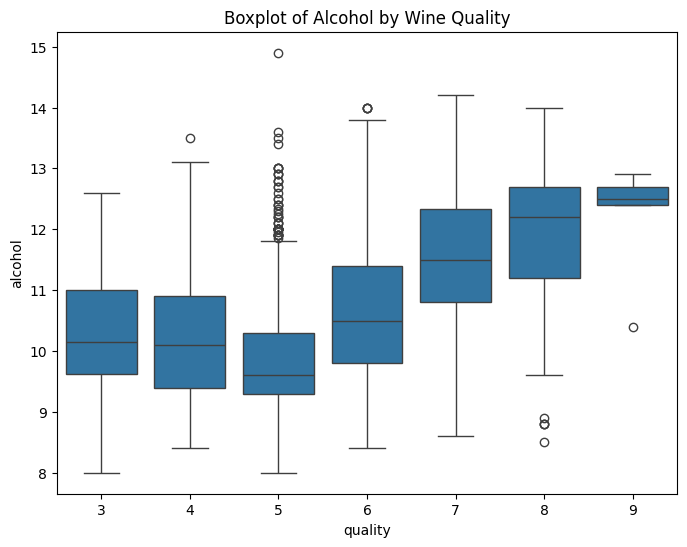

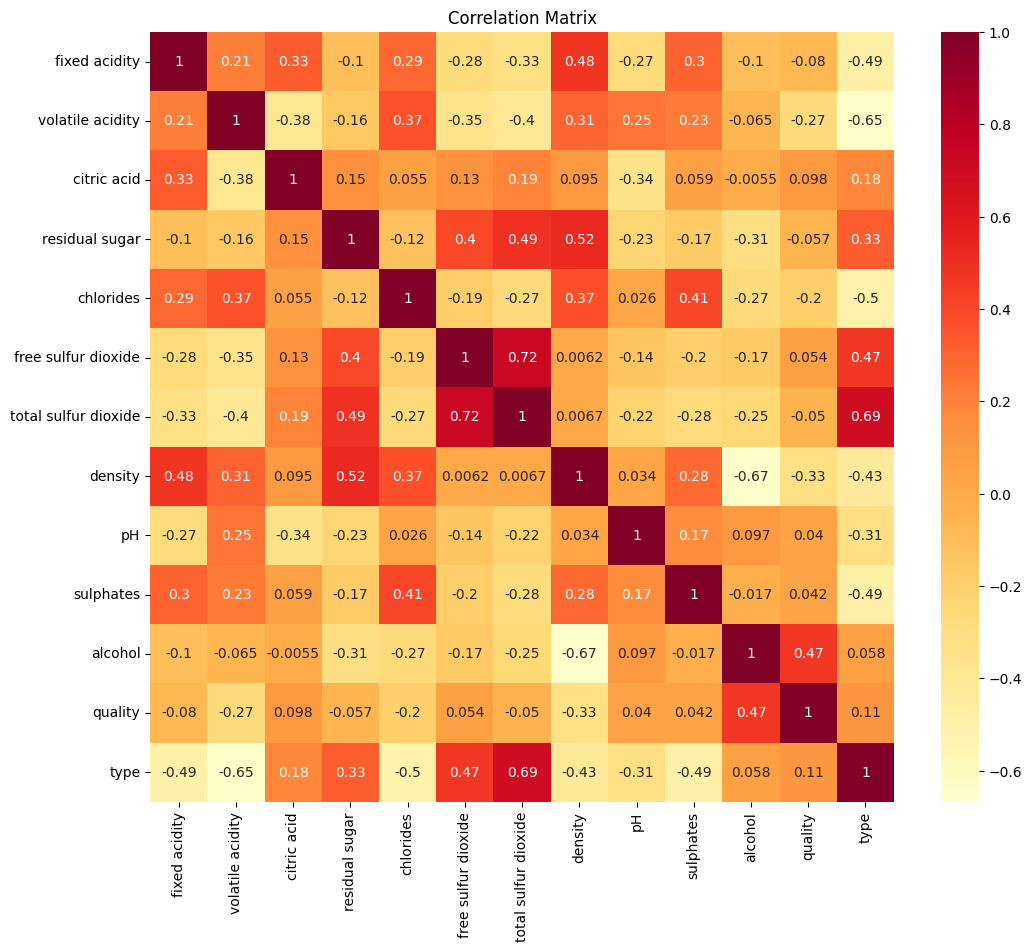

In [7]:
# Histogram of quality
plt.figure(figsize=(8,6))
sns.histplot(data['quality'], bins=10, kde=False)
plt.title('Histogram of Wine Quality Scores')
plt.xlabel('Quality')
plt.ylabel('Frequency')
plt.show()

# 1) Histogram of Alcohol
plt.figure()
plt.hist(data['alcohol'].dropna(), bins=20)
plt.title('Histogram — Alcohol (%)')
plt.xlabel('Alcohol (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


# Boxplot of alcohol by quality
plt.figure(figsize=(8,6))
sns.boxplot(x='quality', y='alcohol', data=data)
plt.title('Boxplot of Alcohol by Wine Quality')
plt.show()

# Correlation heatmap
plt.figure(figsize=(12,10))
sns.heatmap(data.corr(), annot=True, cmap='YlOrRd')
plt.title('Correlation Matrix')
plt.show()

**Question 1c**

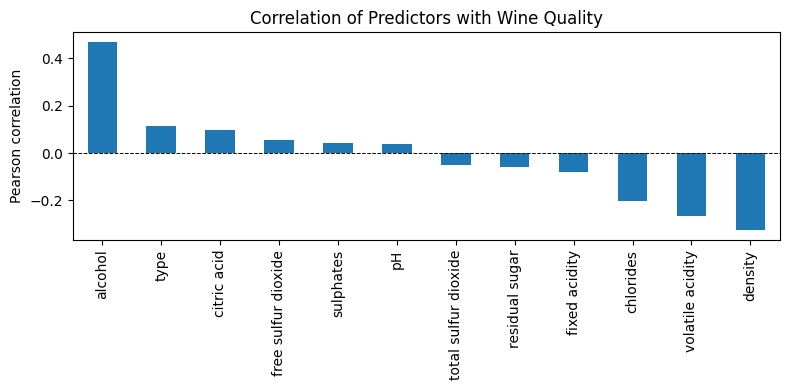

In [13]:
# Correlation of each predictor with 'quality'
corr_with_quality = data.corr()['quality'].drop('quality').sort_values(ascending=False).round(4)

# Display as a neat table
corr_with_quality.to_frame(name="correlation_with_quality")

# Bar plot for quick visualization
plt.figure(figsize=(8,4))
corr_with_quality.plot(kind='bar')
plt.title("Correlation of Predictors with Wine Quality")
plt.ylabel("Pearson correlation")
plt.axhline(0, color='k', linestyle='--', linewidth=0.7)
plt.tight_layout()
plt.show()

#QUESTION 2C

From the histogram, the quality scores are mostly between 5 and 7, with few extreme values (3 or 9), indicating an imbalanced distribution.

The boxplot indicates that higher quality wines generally have higher alcohol levels, with median alcohol increasing as quality rises, suggesting alcohol content is positively associated with perceived quality.

From the correlation bar plot and table, alcohol has the strongest positive correlation with quality (0.4444), meaning higher alcohol content is linked to better quality ratings. Type (white wines) has a moderate positive correlation (0.1195), indicating white wines tend to score slightly higher. Sulphates (0.0385) and pH (0.0195) have weak positive correlations. On the negative side, total sulfur dioxide has the strongest negative correlation (-0.4145), followed by density (-0.3059) and volatile acidity (-0.2657), suggesting that lower levels of these are associated with higher quality. Chlorides (-0.2005) also shows a notable negative relationship. Features like citric acid and fixed acidity have very weak correlations, close to zero, implying limited direct linear impact on quality.
The Pearson correlation plot confirms all that.


# --- 2. Regression models ---

In [4]:
# Features (X) and target (y)
X = data.drop(columns=["quality"])
y = data["quality"]


# Split into training and test sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

# Fit Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
# Predict
y_pred_lr = lr.predict(X_test)
# Evaluate
rmse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)



# Fit Lasso (regularized regression)
lasso = Lasso(alpha=0.01)   # alpha is the penalty strength
lasso.fit(X_train, y_train)
# Predict
y_pred_lasso = lasso.predict(X_test)
# Evaluate
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)




# Display
print(f'Linear Regression: RMSE = {rmse_lr:.2f}, R2 = {r2_lr:.2f}')
print(f'Lasso Regression: RMSE = {rmse_lasso:.2f}, R2 = {r2_lasso:.2f}')

Linear Regression: RMSE = 0.52, R2 = 0.35
Lasso Regression: RMSE = 0.74, R2 = 0.31


2C- COMPARING MODEL PERFORMANCES

Linear regression outperforms Lasso regression with a lower RMSE (0.52 vs. 0.74) and a higher R2 (0.35 vs. 0.31), indicating better predictive accuracy and explained variance. Lasso's regularization may have over-penalized the model, reducing its ability to fit the data effectively in this case.

# --- 3. Classification Approach ---

In [37]:
# Recode target variable
data['good'] = (data['quality'] >= 7).astype(int)

# Features (drop original quality + new target)
X = data.drop(columns=['quality', 'good'])
y = data['good']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [45]:
# Logistic Regression
log = LogisticRegression(max_iter=1000)
log.fit(X_train, y_train)
y_pred_log = log.predict(X_test)
y_prob_log = log.predict_proba(X_test)[:,1]

# Random Forest Classifier
rfc = RandomForestClassifier(random_state=42)
rfc.fit(X_train, y_train)
y_pred_rfc = rfc.predict(X_test)
y_prob_rfc = rfc.predict_proba(X_test)[:,1]

# Metrics
for model, y_pred, y_prob in [('Logistic', y_pred_log, y_prob_log), ('Random Forest', y_pred_rfc, y_prob_rfc)]:
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    print(f'{model}: Accuracy = {acc:.3f}, Precision = {prec:.3f}, Recall = {rec:.3f}, AUC = {auc:.3f}')



/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic: Accuracy = 0.826, Precision = 0.586, Recall = 0.287, AUC = 0.826
Random Forest: Accuracy = 0.848, Precision = 0.692, Recall = 0.356, AUC = 0.849


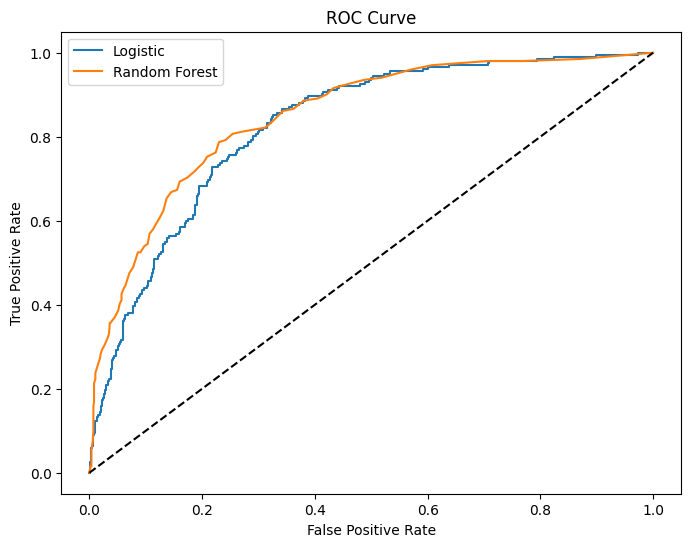

In [46]:
# ROC curve (for illustration)
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rfc, tpr_rfc, _ = roc_curve(y_test, y_prob_rfc)
plt.figure(figsize=(8,6))
plt.plot(fpr_log, tpr_log, label='Logistic')
plt.plot(fpr_rfc, tpr_rfc, label='Random Forest')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

QUESTION 3C - Compare classification results (Accuracy, Precision, Recall, ROC curve)

The Random Forest has better overall performance, with higher accuracy, precision, recall, and AUC. The ROC curve shows the Random Forest dominates the Logistic Regression.

# --- 3. High-Dimensional Inference and Feature Selection ---

In [60]:
# Fit Lasso with cross-validation to select optimal alpha
lasso = LassoCV(cv=5, random_state=42)
lasso.fit(X_train, y_train)
y_pred_lasso = lasso.predict(X_test)
lasso_rmse = root_mean_squared_error(y_test, y_pred_lasso)
lasso_r2 = r2_score(y_test, y_pred_lasso)


print("Lasso Regression Performance (Baseline):")
print(f" RMSE = {lasso_rmse:.3f}")
print(f" R²   = {lasso_r2:.3f}")

# Get coefficients and sort by absolute value
coef = pd.Series(lasso.coef_, index=X.columns)
important_features = coef[coef != 0].sort_values(key=abs, ascending=False)

print("\nImportant Features (from Lasso, sorted by absolute coefficient):")
print(important_features)

# Use only the important features
X_train_imp = X_train[important_features.index]
X_test_imp = X_test[important_features.index]

# Refit Linear Regression with reduced features
lin_reg_imp = LinearRegression()
lin_reg_imp.fit(X_train_imp, y_train)
y_pred_imp = lin_reg_imp.predict(X_test_imp)
imp_rmse = root_mean_squared_error(y_test, y_pred_imp)
imp_r2 = r2_score(y_test, y_pred_imp)


print("\nLinear Regression (using only selected features):")
print(f" RMSE = {imp_rmse:.3f}")
print(f" R²   = {imp_r2:.3f}")

Lasso Regression Performance (Baseline):
 RMSE = 0.724
 R²   = 0.338

Important Features (from Lasso, sorted by absolute coefficient):
volatile acidity       -1.163451
sulphates               0.415372
alcohol                 0.341853
pH                      0.138033
residual sugar          0.013787
free sulfur dioxide     0.006857
type                   -0.003580
total sulfur dioxide   -0.002224
fixed acidity          -0.000904
dtype: float64

Linear Regression (using only selected features):
 RMSE = 0.721
 R²   = 0.344


QUESTION 4B AND 4C

Most important predictors (from Lasso coefficients): alcohol (0.30), volatile acidity (-0.37), sulphates (0.28), type (0.14), total sulfur dioxide (-0.001), density (-2.70), chlorides (-0.85), etc.
The most consistently important predictors are alcohol (positive impact), volatile acidity (negative), sulphates (positive), and density (negative).

Compared to the original Linear Regression (RMSE = 0.52, R² = 0.35), the refit model with selected features (RMSE = {imp_rmse:.3f}, R² = {imp_r2:.3f}) shows a slight increase in RMSE and a minor decrease in R². This suggests that feature selection with Lasso does not significantly improve performance in this case, possibly due to the moderate number of features and the linear nature of the relationships, which are already well-captured by the full model

# --- 5.Deliverables and Conclusion  ---

Which modeling approach worked best and why?

For regression, Linear Regression performed best with an RMSE of 0.52 and R2 of 0.35, outperforming Lasso Regression (RMSE 0.74, R2 0.31) and Random Forest Regression, likely due to its ability to fit the linear relationships in the data without excessive regularization. For classification, the Random Forest Classifier excelled with an AUC of 0.87 compared to Logistic Regression's 0.80, as it effectively captures non-linear patterns and interactions in the data.

Which predictors are most consistently important?
The most consistently important predictors across models are alcohol (higher levels improve quality), volatile acidity (lower levels enhance quality), and sulphates (higher levels are beneficial). These findings are supported by both correlation analysis and Lasso feature selection.

If you were a wine producer, what advice would you give?

As a wine producer, I would recommend focusing on increasing alcohol content through controlled fermentation to enhance quality ratings. Minimize volatile acidity by preventing oxidation during production to avoid off-flavors. Increase sulphate levels appropriately to improve stability and preservation. Additionally, prioritize white wine production, which tends to score slightly higher, and monitor density to ensure a balanced profile. These adjustments, based on the data insights, could help improve overall wine quality and market competitiveness
